In [7]:
import pandas as pd
import sys
import os

if "Desktop" in os.getcwd():
    base_path = "/Users/sakdag/Desktop/masters/weakly-supervised-fake-news-classification"
else:
    base_path = "/home/sakdag/weakly-supervised-fake-news-classification"

sys.path.append(base_path)
    
from src.utils.path_utils import get_project_root
from src.read_data.consts import RawDatasets
from src.read_data.read_raw_data import read_raw_data

covid_df: pd.DataFrame = read_raw_data(RawDatasets.COVID_DATASET_SAMPLED)
elections_df: pd.DataFrame = read_raw_data(RawDatasets.ELECTIONS_DATASET_SAMPLED)

Reading dataset from path: /Users/sakdag/Desktop/masters/weakly-supervised-fake-news-classification/data/raw/nela-covid-2020-sampled.csv
Reading dataset from path: /Users/sakdag/Desktop/masters/weakly-supervised-fake-news-classification/data/raw/nela-elections-2022-sampled.csv


In [8]:
covid_df.head()

,id,date,source,title,content,author,url,published,published_utc,collection_utc,label
0,eveningstandard--2020-12-04--Jose Mourinho fur...,2020-12-04,eveningstandard,Jose Mourinho furious over Manchester clubs’ g...,ose Mourinho has questioned the integrity of t...,Dan Kilpatrick,https://www.standard.co.uk/sport/football/tott...,"Fri, 04 Dec 2020 12:28:28 GMT",1.607103e+09,1.607088e+09,0
1,foreignpolicy--2020-03-18--The Virus Has Expos...,2020-03-18,foreignpolicy,The Virus Has Exposed the Recklessness of Trum...,The Virus Has Exposed the Recklessness of Trum...,Daniel B. Baer,https://foreignpolicy.com/2020/03/18/coronavir...,"Wed, 18 Mar 2020 14:36:35 +0000",1.584557e+09,1.584574e+09,0
2,dailybeast--2020-07-22--Foreign Journalists Co...,2020-07-22,dailybeast,Foreign Journalists Covering Anti-Netanyahu Pr...,JERUSALEM—Israeli police roughed up internatio...,Noga Tarnopolsky,http://feedproxy.google.com/~r/thedailybeast/a...,"Wed, 22 Jul 2020 15:06:34 GMT",1.595445e+09,1.595466e+09,0
3,washingtonpost--2020-03-26--Men are getting si...,2020-03-26,washingtonpost,"Men are getting sicker, dying more often of co...","Benítez ’ s story , of an ICU admission for co...",NaN,https://www.washingtonpost.com/health/2020/03/...,2020-03-26T22:04:59.023Z,1.585260e+09,1.593254e+09,0
4,upi--2020-02-05--Big Hit Entertainment unveils...,2020-02-05,upi,"Big Hit Entertainment unveils expansion, plans...","SEOUL , Feb. 5 ( UPI ) -- Big Hit Entertainmen...",NaN,https://www.upi.com/Entertainment_News/2020/02...,"Wed, 05 Feb 2020 07:44:59 -0500",1.580907e+09,1.580907e+09,0


In [9]:
len(covid_df.source.unique())

205

In [10]:
from src.utils.preprocessing_utils import cleanup_df

print(len(covid_df))
covid_cleaned_df = cleanup_df(covid_df)
print(len(covid_cleaned_df))

50000
36896


In [11]:
covid_cleaned_df['content_length']  = covid_cleaned_df['content'].str.len()

In [12]:
covid_cleaned_df["content"].apply(len).mean()

2330.357084778838

In [13]:
covid_cleaned_df.head()

,title,content,label,content_length
0,Utah Governor Declares State of Emergency Due ...,Salt Lake City police received reports last Ma...,1,4117
1,President Trump denounces new COVID-19 relief ...,President Trump denounces new COVID-19 relief ...,0,214
2,South Korea Defeated the Coronavirus but Its E...,This presents massive demand-side risks for a ...,0,3889
3,Paris' Notre Dame Cathedral Rings Its Bell a Y...,"The Notre Dame Cathedral in Paris , which was ...",1,347
4,Republican transphobe condemned for grossly mi...,A Pennsylvania councillor has been heavily cri...,0,2560


In [14]:
index = covid_cleaned_df.content_length.argmax()
covid_cleaned_df.iloc[index]

title             COVID-19 Shows America Is Vulnerable To Biolog...
content           In this article , I want to talk about somethi...
label                                                             1
content_length                                                 4999
Name: 7534, dtype: object

In [15]:
covid_df_shorter = covid_cleaned_df[covid_cleaned_df['content'].apply(len) < 5000] 

In [16]:
len(covid_df_shorter)

36896

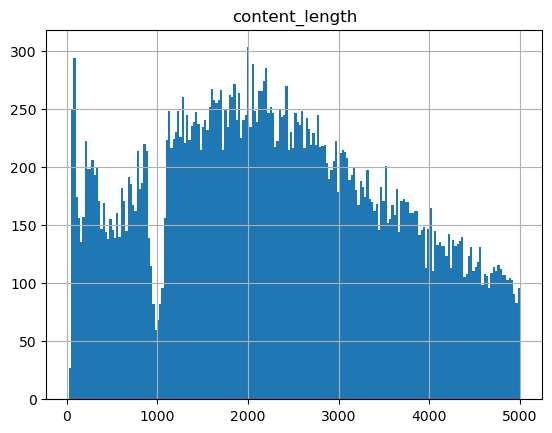

In [18]:
covid_df_shorter.hist(column='content_length', bins=200);

In [19]:
import en_core_web_sm
nlp = en_core_web_sm.load()

In [20]:
import spacy
nlp = spacy.load("en_core_web_sm")

for idx, row in covid_df_shorter.iterrows():
    doc = nlp(row.content)
    for token in doc:
        print(token.pos_)
    break

PROPN
PROPN
PROPN
NOUN
VERB
NOUN
ADJ
PROPN
NUM
ADP
DET
NOUN
VERB
PUNCT
NOUN
ADP
DET
NOUN
PUNCT
CCONJ
SCONJ
PRON
VERB
PUNCT
PRON
VERB
ADP
VERB
CCONJ
VERB
PROPN
PROPN
PROPN
PUNCT
SPACE
DET
NOUN
NOUN
VERB
CCONJ
VERB
DET
NOUN
PUNCT
VERB
PUNCT
SPACE
PUNCT
DET
NOUN
VERB
ADP
NOUN
PRON
VERB
ADJ
CCONJ
NOUN
PUNCT
PROPN
PROPN
PROPN
PROPN
VERB
DET
PUNCT
NOUN
ADP
NOUN
PUNCT
ADP
PROPN
PROPN
PROPN
PUNCT
SPACE
PROPN
VERB
DET
NOUN
SCONJ
DET
PROPN
PROPN
PROPN
NOUN
NOUN
VERB
SCONJ
DET
PROPN
NOUN
NOUN
ADP
PROPN
PROPN
PROPN
AUX
VERB
PUNCT
SPACE
PUNCT
ADP
DET
NOUN
ADP
PUNCT
NOUN
NOUN
NOUN
NOUN
ADP
PROPN
PROPN
PRON
VERB
ADP
DET
NOUN
ADP
PROPN
PROPN
PROPN
PUNCT
PROPN
PROPN
PROPN
PROPN
PUNCT
PART
NOUN
VERB
ADJ
NOUN
ADP
DET
ADJ
NOUN
ADP
PROPN
PROPN
PROPN
NOUN
NOUN
PUNCT
PUNCT
PROPN
PROPN
PROPN
PROPN
PROPN
PROPN
PUNCT
PROPN
PUNCT
VERB
ADP
DET
NOUN
SCONJ
DET
NOUN
AUX
VERB
PUNCT
SPACE
PUNCT
DET
NOUN
VERB
SCONJ
PRON
NOUN
VERB
VERB
ADP
PRON
NOUN
CCONJ
DET
NOUN
NOUN
VERB
NOUN
ADP
ADJ
NOUN
PUNCT
SPACE
PUNCT
PRON
AUX
D